# Step 4: Feature Engineering

The objective of this step is to transform raw customer-level data
into meaningful behavioural features that can help predict credit default.

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

train = pd.read_csv("../data/train.csv")
test  = pd.read_csv("../data/test.csv")
target = "DEFAULT"
print(train.shape, test.shape)

(21000, 24) (9000, 24)


In [4]:
pay_chron  = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]   # Apr -> Sep
bill_chron = [f"BILL_AMT{i}" for i in range(6, 0, -1)]                # Apr -> Sep
amt_chron  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]                 # Apr -> Sep

In [5]:
print(pay_chron)
print(bill_chron)
print(amt_chron)

['PAY_6', 'PAY_5', 'PAY_4', 'PAY_3', 'PAY_2', 'PAY_0']
['BILL_AMT6', 'BILL_AMT5', 'BILL_AMT4', 'BILL_AMT3', 'BILL_AMT2', 'BILL_AMT1']
['PAY_AMT6', 'PAY_AMT5', 'PAY_AMT4', 'PAY_AMT3', 'PAY_AMT2', 'PAY_AMT1']


In [6]:
#slope across six months
def row_slope(values: np.ndarray) -> np.ndarray:
    """Slope per row of a (n_rows x 6) array, oldest month first."""
    x = np.arange(values.shape[1], dtype=float)
    xc = x - x.mean()
    return (values - values.mean(axis=1, keepdims=True)) @ xc / (xc @ xc)

In [7]:
#Family 1: Delinquency features
def delinquency_features(d):
    f = pd.DataFrame(index=d.index)
    late = d[pay_chron].clip(lower=0)             # months late, 0 if not late

    f["pay0_raw"]        = d["PAY_0"]                          # raw status, for binning
    f["delay_latest"]    = late["PAY_0"].clip(upper=3)         # capped at 3+ (rare above)
    f["n_late_months"]   = (late > 0).sum(axis=1)              # persistence, 0..6
    f["n_late_last3"]    = (late[pay_chron[-3:]] > 0).sum(axis=1)   # recent persistence
    f["max_delay"]       = late.max(axis=1).clip(upper=3)      # worst severity
    f["avg_delay"]       = late.mean(axis=1)
    f["delay_trend"]     = row_slope(late.values)              # >0 = getting worse
    f["delay_recent_vs_old"] = late[pay_chron[-3:]].mean(axis=1) - late[pay_chron[:3]].mean(axis=1)

    # months since most recent late month (0 = late in Sep, 6 = never late)
    is_late = (late.values > 0)
    last_idx = np.where(is_late.any(axis=1), 5 - np.argmax(is_late[:, ::-1], axis=1), -1)
    f["months_since_late"] = np.where(last_idx >= 0, 5 - last_idx, 6)

    f["ever_late"]       = (f["n_late_months"] > 0).astype(int)
    f["n_revolving"]     = (d[pay_chron] == 0).sum(axis=1)     # months paying only min (code 0)
    f["n_paid_full"]     = (d[pay_chron] == -1).sum(axis=1)    # months paid in full (code -1)
    f["n_no_use"]        = (d[pay_chron] == -2).sum(axis=1)    # months with no consumption
    return f

In [8]:
#Family 2: Utilization features
def utilization_features(d):
    f = pd.DataFrame(index=d.index)
    lim = d["LIMIT_BAL"]
    util = d[bill_chron].clip(lower=0).div(lim, axis=0).clip(upper=1.5)   # Apr..Sep, 0..150%

    f["util_latest"]   = util["BILL_AMT1"]
    f["util_avg"]      = util.mean(axis=1)
    f["util_max"]      = util.max(axis=1)
    f["util_trend"]    = row_slope(util.values)
    f["util_avg_last3"] = util[bill_chron[-3:]].mean(axis=1)
    f["n_over_limit"]  = (d[bill_chron].gt(lim, axis=0)).sum(axis=1)
    f["n_zero_bill"]   = (d[bill_chron] <= 0).sum(axis=1)
    f["has_credit_bal"] = (d[bill_chron] < 0).any(axis=1).astype(int)
    f["limit_bal"]     = lim
    f["log_limit"]     = np.log(lim)
    return f

In [9]:
#Family 3: Payment behavior features
def payment_features(d):
    f = pd.DataFrame(index=d.index)

    # chronological pairs: payment in month k vs. bill from month k-1
    # PAY_AMT5 (May) <- BILL_AMT6 (Apr) ... PAY_AMT1 (Sep) <- BILL_AMT2 (Aug)
    pay_cols_p  = [f"PAY_AMT{i}"  for i in range(5, 0, -1)]
    bill_cols_p = [f"BILL_AMT{i}" for i in range(6, 1, -1)]

    P = d[pay_cols_p].values.astype(float)
    B = d[bill_cols_p].values.astype(float)

    valid = B > 0                                   # ratio defined only with a positive prior bill
    ratio = np.full(P.shape, np.nan)
    ratio[valid] = P[valid] / B[valid]
    ratio = np.clip(ratio, 0, 1.5)                  # cap at 150% (paying more than owed)

    R = pd.DataFrame(ratio, index=d.index, columns=[f"r{i}" for i in range(5, 0, -1)])

    f["pay_ratio_latest"]  = R["r1"]                              # Sep payment / Aug bill
    f["pay_ratio_avg"]     = R.mean(axis=1)                       # NaN-skipping mean
    f["pay_ratio_min"]     = R.min(axis=1)
    f["pay_ratio_last3"]   = R[["r3", "r2", "r1"]].mean(axis=1)
    f["n_valid_ratios"]    = valid.sum(axis=1)
    f["no_prior_bill_latest"] = (~valid[:, -1]).astype(int)       # flag: ratio undefined

    f["n_paid_zero"]       = (d[pay_cols_p] == 0).sum(axis=1)
    f["n_paid_zero_with_bill"] = ((P == 0) & valid).sum(axis=1)   # paid nothing despite owing
    f["n_paid_full_cov"]   = ((P >= B) & valid).sum(axis=1)       # paid at least the whole prior bill
    f["n_min_payer"]       = ((ratio > 0) & (ratio < 0.2)).sum(axis=1)  # paid <20% of bill

    # cash-flow view, avoids ratio problems
    f["total_paid_over_billed"] = d[pay_cols_p].sum(axis=1) / (d[bill_cols_p].clip(lower=0).sum(axis=1).replace(0, np.nan))
    f["pay_amt_avg"]       = d[amt_chron].mean(axis=1)
    f["pay_amt_trend"]     = row_slope(d[amt_chron].values.astype(float))
    f["pay_amt_latest_vs_avg"] = d["PAY_AMT1"] / (d[amt_chron].mean(axis=1).replace(0, np.nan))
    f["pay_ratio_to_limit"] = d["PAY_AMT1"] / d["LIMIT_BAL"]
    return f

In [10]:
#Family 4: Bill dynamics
def bill_features(d):
    f = pd.DataFrame(index=d.index)
    B = d[bill_chron].values.astype(float)
    lim = d["LIMIT_BAL"].values

    f["bill_avg"]        = B.mean(axis=1)
    f["bill_avg_to_limit"] = B.mean(axis=1) / lim
    f["bill_change_6m"]  = (d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]   # scaled by limit
    f["bill_trend"]      = row_slope(B) / lim                                    # scaled slope
    f["bill_cv"]         = B.std(axis=1) / np.where(np.abs(B.mean(axis=1)) > 1, np.abs(B.mean(axis=1)), np.nan)
    f["bill_latest_vs_avg"] = d["BILL_AMT1"] / np.where(np.abs(B.mean(axis=1)) > 1, B.mean(axis=1), np.nan)
    f["n_bill_increases"] = (np.diff(B, axis=1) > 0).sum(axis=1)                 # months bill went up
    return f

In [11]:
#Family 5: Profile and combined features
def profile_features(d):
    f = pd.DataFrame(index=d.index)
    f["age"] = d["AGE"]                      # candidate only: tested later (Step 6)
    f["education"] = d["EDUCATION"]
    f["dormant"] = ((d[bill_chron] == 0).all(axis=1) & (d[amt_chron] == 0).all(axis=1)).astype(int)

    late_latest = d["PAY_0"].clip(lower=0)
    util_latest = (d["BILL_AMT1"].clip(lower=0) / d["LIMIT_BAL"]).clip(upper=1.5)
    f["late_and_high_util"] = ((late_latest >= 1) & (util_latest >= 0.8)).astype(int)
    return f

In [12]:
def build_features(d):
    parts = [delinquency_features(d), utilization_features(d),
             payment_features(d), bill_features(d), profile_features(d)]
    X = pd.concat(parts, axis=1)
    X = X.replace([np.inf, -np.inf], np.nan)      # safety net; should be none
    return X

In [13]:
X_train = build_features(train.drop(columns=[target]))
X_test = build_features(test.drop(columns=[target]))

y_train = train[target]
y_test = test[target]

print(X_train.shape)
print(X_test.shape)

assert list(X_train.columns) == list(X_test.columns)

(21000, 49)
(9000, 49)


In [14]:
health = pd.DataFrame({
    "missing_%": X_train.isna().mean() * 100,
    "n_unique": X_train.nunique(),
    "min": X_train.min(),
    "median": X_train.median(),
    "max": X_train.max()
}).round(3)

health

,missing_%,n_unique,min,median,max
pay0_raw,0.000,11,-2.000,0.000,8.000
delay_latest,0.000,4,0.000,0.000,3.000
n_late_months,0.000,7,0.000,0.000,6.000
n_late_last3,0.000,4,0.000,0.000,3.000
max_delay,0.000,4,0.000,0.000,3.000
avg_delay,0.000,35,0.000,0.000,6.000
delay_trend,0.000,86,-1.371,0.000,1.143
delay_recent_vs_old,0.000,58,-4.667,0.000,3.333
months_since_late,0.000,7,0.000,6.000,6.000
ever_late,0.000,2,0.000,0.000,1.000


In [15]:
np.isinf(
    X_train.select_dtypes("number")
).sum().sum()

np.int64(0)

In [16]:
cmp = pd.DataFrame({
    "train_mean": X_train.mean(),
    "test_mean": X_test.mean(),
    "train_missing_%": X_train.isna().mean() * 100,
    "test_missing_%": X_test.isna().mean() * 100
})

cmp["mean_diff_%"] = (
    100 * (cmp["test_mean"] - cmp["train_mean"]).abs()
    / cmp["train_mean"].abs().replace(0, np.nan)
)

cmp.sort_values(
    "mean_diff_%",
    ascending=False
).head(10)

,train_mean,test_mean,train_missing_%,test_missing_%,mean_diff_%
pay0_raw,-0.015,-0.020,0.000,0.000,33.124
pay_amt_trend,164.483,188.142,0.000,0.000,14.384
total_paid_over_billed,0.436,0.388,4.624,4.833,10.946
bill_cv,0.644,0.575,2.905,2.911,10.683
late_and_high_util,0.070,0.075,0.000,0.000,7.435
no_prior_bill_latest,0.104,0.109,0.000,0.000,4.792
delay_recent_vs_old,0.093,0.088,0.000,0.000,4.756
delay_trend,0.029,0.027,0.000,0.000,4.236
has_credit_bal,0.065,0.062,0.000,0.000,4.142
util_trend,0.022,0.022,0.000,0.000,2.241


In [17]:
train.loc[
    [0, 1, 2],
    [
        "PAY_6", "PAY_5", "PAY_4",
        "PAY_3", "PAY_2", "PAY_0",
        "BILL_AMT1", "BILL_AMT2",
        "PAY_AMT1", "LIMIT_BAL"
    ]
]

,PAY_6,PAY_5,PAY_4,PAY_3,PAY_2,PAY_0,BILL_AMT1,BILL_AMT2,PAY_AMT1,LIMIT_BAL
0,0,0,0,0,0,0,156098,156259,6000,160000
1,0,2,0,0,0,0,28383,32903,5000,100000
2,0,0,0,0,0,0,73722,75323,3300,80000


In [18]:
X_train.loc[[0, 1, 2], "n_late_months"]

0    0
1    1
2    0
Name: n_late_months, dtype: int64

In [19]:
X_train.loc[[0, 1, 2], "util_latest"]


0   0.976
1   0.284
2   0.922
Name: util_latest, dtype: float64

In [20]:
X_train.loc[[0, 1, 2], "pay_ratio_latest"]

0   0.038
1   0.152
2   0.044
Name: pay_ratio_latest, dtype: float64

In [21]:
rows = []

for c in X_train.columns:
    s = X_train[c]
    mask = s.notna()

    if mask.sum() < 1000 or s[mask].nunique() < 2:
        continue

    auc = roc_auc_score(y_train[mask], s[mask])

    rows.append((
        c,
        auc,
        max(auc, 1 - auc),
        100 * (~mask).mean()
    ))

sig = pd.DataFrame(
    rows,
    columns=["feature", "auc", "strength", "missing_%"]
).sort_values(
    "strength",
    ascending=False
)

sig.head(15)

,feature,auc,strength,missing_%
5,avg_delay,0.733,0.733,0.000
2,n_late_months,0.731,0.731,0.000
8,months_since_late,0.277,0.723,0.000
4,max_delay,0.721,0.721,0.000
3,n_late_last3,0.717,0.717,0.000
9,ever_late,0.705,0.705,0.000
1,delay_latest,0.702,0.702,0.000
0,pay0_raw,0.692,0.692,0.000
25,pay_ratio_min,0.323,0.677,4.624
30,n_paid_zero_with_bill,0.651,0.651,0.000


In [22]:
sig.to_csv("../reports/engineered_feature_signal.csv", index=False)

In [23]:
corr = X_train.corr(method="spearman")

pairs = (
    corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )
    .stack()
    .rename("corr")
    .reset_index()
    .query("abs(corr) > 0.85")
    .sort_values("corr", key=abs, ascending=False)
)

pairs.head(20)

,level_0,level_1,corr
1051,limit_bal,log_limit,1.000
725,util_avg,bill_avg_to_limit,0.999
825,util_trend,bill_trend,0.998
103,n_late_months,avg_delay,0.998
201,max_delay,avg_delay,0.988
1209,pay_ratio_avg,total_paid_over_billed,0.985
205,max_delay,ever_late,0.982
102,n_late_months,max_delay,0.981
958,n_zero_bill,n_valid_ratios,-0.981
401,months_since_late,ever_late,-0.981


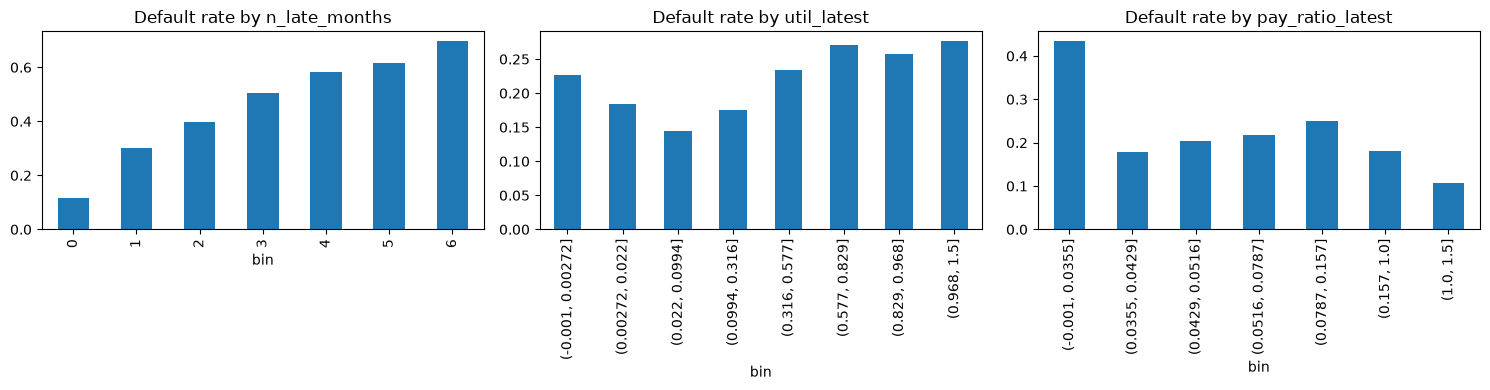

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for a, c in zip(
    ax,
    ["n_late_months", "util_latest", "pay_ratio_latest"]
):
    d = X_train[[c]].assign(y=y_train)

    d["bin"] = (
        pd.qcut(d[c], 8, duplicates="drop")
        if d[c].nunique() > 8
        else d[c]
    )

    d.groupby("bin", observed=True)["y"].mean().plot(
        kind="bar",
        ax=a,
        title=f"Default rate by {c}"
    )

plt.tight_layout()

plt.savefig(
    "../reports/figures/engineered_features_check.png",
    bbox_inches="tight"
)

plt.show()

In [25]:
fd = pd.DataFrame({
    "feature": X_train.columns
})

fd.to_csv(
    "../reports/feature_dictionary_skeleton.csv",
    index=False
)

In [26]:
X_train.assign(
    DEFAULT=y_train.values
).to_csv(
    "../data/features_train.csv",
    index=False
)

X_test.assign(
    DEFAULT=y_test.values
).to_csv(
    "../data/features_test.csv",
    index=False
)

In [27]:
from importlib import reload
import sys

# Tell Python where the src folder is
sys.path.append("../src")

# Import our feature-engineering file
import features

# Reload it so Python uses the latest saved version
reload(features)

<module 'features' from 'C:\\Users\\Vaidehi Kushwaha\\Documents\\credit-risk-scorecard-profit-optimization\\notebooks\\../src\\features.py'>

In [28]:
# Keep the target variable separate from the input features
target = "DEFAULT"

# Create features for the training data
X_train = features.build_features(train.drop(columns=[target]))

# Create features for the testing data
X_test = features.build_features(test.drop(columns=[target]))

# Keep the actual target values separately
y_train = train[target]
y_test = test[target]

In [29]:
#chech feature creation
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nFirst five training rows:")
display(X_train.head())

Training feature shape: (21000, 49)
Testing feature shape: (9000, 49)

First five training rows:


,pay0_raw,delay_latest,n_late_months,n_late_last3,max_delay,avg_delay,delay_trend,delay_recent_vs_old,months_since_late,ever_late,n_revolving,n_paid_full,n_no_use,util_latest,util_avg,util_max,util_trend,util_avg_last3,n_over_limit,n_zero_bill,has_credit_bal,limit_bal,log_limit,pay_ratio_latest,pay_ratio_avg,pay_ratio_min,pay_ratio_last3,n_valid_ratios,no_prior_bill_latest,n_paid_zero,n_paid_zero_with_bill,n_paid_full_cov,n_min_payer,total_paid_over_billed,pay_amt_avg,pay_amt_trend,pay_amt_latest_vs_avg,pay_ratio_to_limit,bill_avg,bill_avg_to_limit,bill_change_6m,bill_trend,bill_cv,bill_latest_vs_avg,n_bill_increases,age,education,dormant,late_and_high_util
0,0,0,0,0,0,0.000,0.000,0.000,6,0,6,0,0,0.976,0.972,0.980,0.000,0.975,0,0,0,160000,11.983,0.038,0.038,0.037,0.038,5,0,0,0,0,5,0.038,"5,850.000",60.000,1.026,0.037,"155,590.667",0.972,0.002,0.000,0.007,1.003,3,32,2,0,0
1,0,0,1,0,2,0.333,-0.171,-0.667,4,1,5,0,0,0.284,0.430,0.526,-0.052,0.345,0,0,0,100000,11.513,0.152,0.127,0.000,0.194,5,0,1,1,0,3,0.121,"4,963.667","1,336.629",1.007,0.050,"43,046.500",0.430,-0.242,-0.052,0.220,0.659,1,30,1,0,0
2,0,0,0,0,0,0.000,0.000,0.000,6,0,6,0,0,0.922,0.716,0.942,0.097,0.889,0,0,0,80000,11.290,0.044,0.038,0.034,0.039,5,0,0,0,0,5,0.039,"2,026.000",318.743,1.629,0.041,"57,302.000",0.716,0.386,0.097,0.249,1.287,3,29,1,0,0
3,0,0,0,0,0,0.000,0.000,0.000,6,0,2,2,2,0.364,0.085,0.364,0.062,0.170,0,3,0,20000,9.903,0.466,0.733,0.466,0.733,2,0,3,0,1,0,0.607,297.667,210.571,3.380,0.050,"1,704.333",0.085,0.364,0.062,1.532,4.275,3,27,2,0,0
4,-2,0,0,0,0,0.000,0.000,0.000,6,0,0,0,6,0.000,0.007,0.041,0.004,0.014,0,5,0,50000,10.820,1.000,1.000,1.000,1.000,1,0,4,0,1,0,1.000,345.000,295.714,6.000,0.041,345.000,0.007,0.000,0.004,2.236,0.000,1,30,1,0,0


In [30]:
#check missing and infinite values
health = pd.DataFrame({
    "missing_%": X_train.isna().mean() * 100,
    "n_unique": X_train.nunique(),
    "min": X_train.min(),
    "median": X_train.median(),
    "max": X_train.max()
}).round(3)

display(health)

,missing_%,n_unique,min,median,max
pay0_raw,0.000,11,-2.000,0.000,8.000
delay_latest,0.000,4,0.000,0.000,3.000
n_late_months,0.000,7,0.000,0.000,6.000
n_late_last3,0.000,4,0.000,0.000,3.000
max_delay,0.000,4,0.000,0.000,3.000
avg_delay,0.000,35,0.000,0.000,6.000
delay_trend,0.000,86,-1.371,0.000,1.143
delay_recent_vs_old,0.000,58,-4.667,0.000,3.333
months_since_late,0.000,7,0.000,6.000,6.000
ever_late,0.000,2,0.000,0.000,1.000


In [31]:
np.isinf(X_train.select_dtypes("number")).sum().sum()

np.int64(0)

In [32]:
#Compare training and testing features
comparison = pd.DataFrame({
    "train_mean": X_train.mean(),
    "test_mean": X_test.mean(),
    "train_missing_%": X_train.isna().mean() * 100,
    "test_missing_%": X_test.isna().mean() * 100
})

display(comparison.round(3))

,train_mean,test_mean,train_missing_%,test_missing_%
pay0_raw,-0.015,-0.020,0.000,0.000
delay_latest,0.348,0.344,0.000,0.000
n_late_months,0.839,0.823,0.000,0.000
n_late_last3,0.518,0.509,0.000,0.000
max_delay,0.658,0.648,0.000,0.000
avg_delay,0.281,0.281,0.000,0.000
delay_trend,0.029,0.027,0.000,0.000
delay_recent_vs_old,0.093,0.088,0.000,0.000
months_since_late,4.278,4.318,0.000,0.000
ever_late,0.338,0.331,0.000,0.000


In [33]:
X_train.assign(DEFAULT=y_train.values).to_csv(
    "../data/features_train.csv",
    index=False
)

X_test.assign(DEFAULT=y_test.values).to_csv(
    "../data/features_test.csv",
    index=False
)

print("Feature datasets saved successfully.")

Feature datasets saved successfully.
